# [Link to GitHub Repository](https://github.com/L-nsamba/group-1-formative-3-probability-bayes-gradient-descent.git)

### Importing the relevant and accepted libraries that will be used during the subsequent calculations

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import approx_fprime

### Implementing the initial data provided in rubric in code form


In [2]:
# Input matrix
X = np.array([
    [1, 3],
    [4, 10]
], dtype=float)

# Actual output values
y = np.array([5, 6], dtype=float)

# Initial weights and bias
m = np.array([-1, 2], dtype=float)
b = np.array([1.0, 1.0], dtype=float)

# Learning rate and number of iterations
alpha = 0.01
iterations = 3 # Corresponding to the number of team members

# Number of observations
n = len(y)

# Verifying the output
print("Input matrix X:\n", X)
print("Actual outputs y:", y)
print("Initial weights m:", m)
print("Initial bias b:", b)
print("Learning rate:", alpha)
print("Number of iterations:", n)

Input matrix X:
 [[ 1.  3.]
 [ 4. 10.]]
Actual outputs y: [5. 6.]
Initial weights m: [-1.  2.]
Initial bias b: [1. 1.]
Learning rate: 0.01
Number of iterations: 2


### Definition of the predictions and MSE calculations

In [3]:
# Formula for y_hat from the linear equation y = mx +b
y_hat = X @ m + b

# Prediction error
p_error = y_hat - y

# Mean square error calculation
mse = np.sum((y_hat - y) ** 2) / n

print("Initial predictions:", y_hat)
print("Prediction errors:", p_error)
print(f"Initial MSE: {mse:.2f}") # 2 decimal places

Initial predictions: [ 6. 17.]
Prediction errors: [ 1. 11.]
Initial MSE: 61.00


### Definition of the MSE cost function

In [4]:
def cost_function(params, X, y):
  # Extracting the weights and bias' from each parameter of the array
  m1 = params[0]
  m2 = params[1]
  b1 = params[2]
  b2 = params[3]

  # Calculation of the predictions
  # Each observation has its own bias
  y_hat = X @ np.array([m1, m2]) + np.array([b1, b2])

  # Calculation and retrieving the value of the MSE
  mse = np.sum((y_hat - y) ** 2) / len(y)

  return mse

# Combining the inital parameters into one array
params = np.array([m[0], m[1], b[0], b[1]], dtype=float)

print("Initial cost:", cost_function(params, X, y))

Initial cost: 61.0


### Using SciPy to approximate the derivatives. This is what we use to get gradients for m1, m2 and b (dJ/dm1, dJ/dm2, dJ/db)

In [5]:
# Small step used for numerical differentiation
epsilon = 1e-8

# Approximating the gradient of the cost function
# where fprime is the derivative of f
def compute_derivative(func, params, *args, eps=epsilon):
  return approx_fprime(params, func, eps, *args)

# Passing the MSE cost function into the derivative function
gradient = compute_derivative(cost_function, params, X, y)

print(f"Gradient for m1: {gradient[0]:.2f}")
print(f"Gradient for m2: {gradient[1]:.2f}")
print(f"Gradient for b1: {gradient[2]:.2f}")
print(f"Gradient for b2: {gradient[3]:.2f}")

Gradient for m1: 45.00
Gradient for m2: 113.00
Gradient for b1: 1.00
Gradient for b2: 11.00


### Calculating the gradients visibly with chain rule for the MSE cost function. This will give us the same answers as the previous cell where we made use of SciPy

In [6]:
# Calculating each gradient explicitly using the chain rule
# where X[:, 0] and X[:, 1] are the equivalent of x1 and x2 respectively
dm1 = (2 / n) * np.sum(p_error * X[:, 0])
dm2 = (2 / n) * np.sum(p_error * X[:, 1])

# Each bias is associated with its own observation
db = (2 / n) * p_error

print(f"Prediction errors: {p_error}")
print(f"Gradient for m1: {dm1:.2f}")
print(f"Gradient for m2: {dm2:.2f}")
print(f"Gradient for b1: {db[0]:.2f}")
print(f"Gradient for b2: {db[1]:.2f}")

Prediction errors: [ 1. 11.]
Gradient for m1: 45.00
Gradient for m2: 113.00
Gradient for b1: 1.00
Gradient for b2: 11.00


### Implementing the three gradient descent updates

In [7]:
# Storing the initial values for tracking
m_history = [m.copy()]
b_history = [b.copy()]

# Calculating the initial MSE
y_hat = X @ m + b
mse = np.sum((y_hat - y) ** 2) / n
mse_history = [mse]

for iteration in range(1, iterations + 1):

  # Calculating predictions and errors before the update
  y_hat = X @ m + b
  errors = y_hat - y
  mse_before = np.sum(errors ** 2) / n

  # Calculating gradients using the chain rule
  dm1 = (2 / n) * np.sum(errors * X[:, 0])
  dm2 = (2 / n) * np.sum(errors * X[:, 1])
  db = (2 / n) * errors

  # Verifying the manual gradients against SciPy
  # Current (pre-update) parameters
  scipy_grad = compute_derivative(cost_function, np.array([m[0], m[1], b[0], b[1]]), X, y)
  manual_grad = np.array([dm1, dm2, db[0], db[1]])
  grads_match = np.allclose(scipy_grad, manual_grad, atol=1e-4) # where atol is the absolute tolerance

  # Updating each parameter
  m[0] = m[0] - alpha * dm1
  m[1] = m[1] - alpha * dm2
  b[0] = b[0] - alpha * db[0]
  b[1] = b[1] - alpha * db[1]

  # Calculating predictions and MSE after the update
  y_hat = X @ m + b
  mse_after = np.sum((y_hat - y) ** 2) / n

  # Storing the updated parameters
  m_history.append(m.copy())
  b_history.append(b.copy())
  mse_history.append(mse_after)

  # Displaying the results
  print(f"\nIteration {iteration}")
  print(f"MSE before update: {mse_before:.2f}")
  print(f"Gradient m1: {dm1:.2f}")
  print(f"Gradient m2: {dm2:.2f}")
  print(f"Gradient b1: {db[0]:.2f}")
  print(f"Gradient b2: {db[1]:.2f}")
  print(f"SciPy gradient: {np.round(scipy_grad, 2)}")
  print(f"SciPy matches manual: {grads_match}")
  print(f"Updated m1: {m[0]:.2f}")
  print(f"Updated m2: {m[1]:.2f}")
  print(f"Updated b1: {b[0]:.2f}")
  print(f"Updated b2: {b[1]:.2f}")
  print(f"Predictions after update: {y_hat}")
  print(f"MSE after update: {mse_after:.2f}")


Iteration 1
MSE before update: 61.00
Gradient m1: 45.00
Gradient m2: 113.00
Gradient b1: 1.00
Gradient b2: 11.00
SciPy gradient: [ 45. 113.   1.  11.]
SciPy matches manual: True
Updated m1: -1.45
Updated m2: 0.87
Updated b1: 0.99
Updated b2: 0.89
Predictions after update: [2.15 3.79]
MSE after update: 6.50

Iteration 2
MSE before update: 6.50
Gradient m1: -11.69
Gradient m2: -30.65
Gradient b1: -2.85
Gradient b2: -2.21
SciPy gradient: [-11.69 -30.65  -2.85  -2.21]
SciPy matches manual: True
Updated m1: -1.33
Updated m2: 1.18
Updated b1: 1.02
Updated b2: 0.91
Predictions after update: [3.2149 7.3447]
MSE after update: 2.50

Iteration 3
MSE before update: 2.50
Gradient m1: 3.59
Gradient m2: 8.09
Gradient b1: -1.79
Gradient b2: 1.34
SciPy gradient: [ 3.59  8.09 -1.79  1.34]
SciPy matches manual: True
Updated m1: -1.37
Updated m2: 1.10
Updated b1: 1.04
Updated b2: 0.90
Predictions after update: [2.954063 6.378335]
MSE after update: 2.16


### Verifying the final iteration (3) results for weight, bias, predictions and MSE

In [8]:
# Calculating predictions and MSE using the final parameters
final_y_hat = X @ m + b
final_mse = np.sum((final_y_hat - y) ** 2) / n

print("Final weights:", np.round(m, 2))
print("Final biases:", np.round(b, 2))
print(f"Final predictions:", np.round(final_y_hat, 2))
print(f"Final MSE: {final_mse:.2f}")

Final weights: [-1.37  1.1 ]
Final biases: [1.04 0.9 ]
Final predictions: [2.95 6.38]
Final MSE: 2.16


### A plot showing how weights (m1, m2) and bias (b) change over iterations

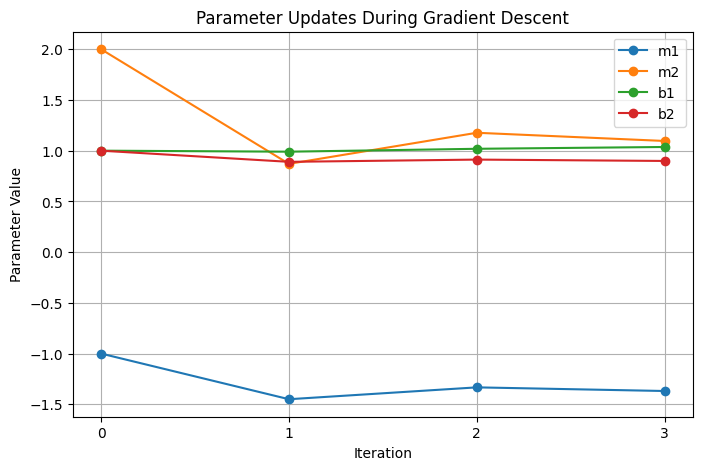

In [9]:
# Plotting parameter updates across iterations
iteration_numbers = range(len(m_history))

plt.figure(figsize=(8, 5))

# m1 plots
plt.plot(iteration_numbers, [m[0] for m in m_history], marker='o', label='m1')

# m2 plots
plt.plot(iteration_numbers, [m[1] for m in m_history], marker='o', label='m2')

# b1 plot
plt.plot(iteration_numbers,[values[0] for values in b_history], marker='o', label='b1')

# b2 plot
plt.plot(iteration_numbers,[values[1] for values in b_history], marker='o', label='b2')

plt.xlabel('Iteration')
plt.ylabel('Parameter Value')
plt.title('Parameter Updates During Gradient Descent')
plt.xticks(iteration_numbers)
plt.legend()
plt.grid(True)
plt.show()

### Interpretation of the parameter updates during gradient descent

The plot shows how the model's weights and bias change over the three gradient descent iterations. The value of m1 becomes more negative after the first update, while the value of m2 decreases significantly before partially increasing in the following iterations. The bias also decreases slightly from its initial value. These changes show how the gradient descent adjusts the model parameters to reduce prediction error

### A plot showing how the error (mse) changes over iterations.

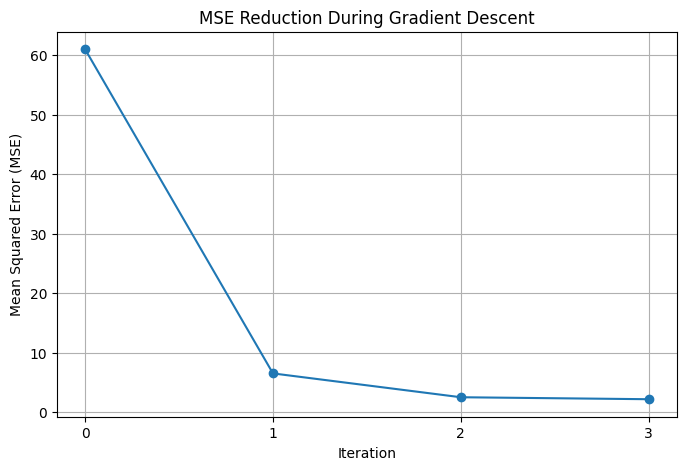

In [10]:
# Plotting MSE across iterations
iteration_numbers = range(len(mse_history))

plt.figure(figsize=(8, 5))

plt.plot(iteration_numbers, mse_history, marker='o')

plt.xlabel('Iteration')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('MSE Reduction During Gradient Descent')
plt.xticks(iteration_numbers)
plt.grid(True)
plt.show()

### Interpretation of the mse reduction during gradient descent

The plot shows a substantial decrease in MSE from 61.00 initially to 2.39 after three iterations. The largest improvement occurs after the first update, with further reductions in the following iterations. This indicates that the model's predictions are getting closer to the actual values as gradient descent updates its parameters

### Conclusion

Gradient descent was implemented to optimize the weights and bias of the linear regression model over three iterations. The results showed the MSE decreased from 61.00 initially to 2.39 after the final update, indicating an improvement in the model's predictions. The visualizations also show how the parameters changed during the optimization process. This activity shows how gradient calculations and parameter updates work together to minimize prediction errors. Additionally, the manual calculation of all these steps will be accessible in the project repository